# Transfer Learning trong NLP

## 1. Thế nào là Transfer Learning?

* **Transfer Learning** là tận dụng kiến thức mà một mô hình đã học được từ một tác vụ/miền dữ liệu (thường là tập dữ liệu lớn, tổng quát) để áp dụng cho một tác vụ khác (thường là tập dữ liệu nhỏ hơn, chuyên biệt hơn).
* **Fine-Tuning** là một kỹ thuật cụ thể để thực hiện Transfer Learning: tiếp tục huấn luyện (cập nhật trọng số) của mô hình pretrained trên dữ liệu của tác vụ mới, thay vì chỉ dùng nó như một bộ trích xuất đặc trưng cố định.

---

## 2. Hai chế độ chính: Feature Extraction vs Fine-Tuning

### Feature Extraction (Đóng băng — Freeze)

* Đóng băng toàn bộ (hoặc gần như toàn bộ) trọng số của mô hình pretrained.
* Chỉ dùng mô hình như một hàm biến đổi đầu vào thành vector đặc trưng (embedding).
* Gắn thêm một "head" nhỏ (thường là 1-2 lớp Linear/MLP) phía sau, và **chỉ huấn luyện phần head này**.
* **Ưu điểm:** Nhanh, ít tốn tài nguyên, ít nguy cơ overfitting khi dataset nhỏ.
* **Nhược điểm:** Mô hình nền không thể "thích nghi" với đặc thù ngôn ngữ/miền của tác vụ mới, dẫn đến hiệu năng trần thấp hơn.

### Fine-Tuning (Tinh chỉnh toàn bộ hoặc một phần)

* Cho phép gradient lan truyền ngược vào cả backbone (toàn bộ hoặc một số layer cuối), cập nhật trọng số pretrained.
* Cần learning rate rất nhỏ để tránh phá vỡ ("catastrophic forgettingcác đặc trưng ngôn ngữ tổng quát đã học được.
* **Ưu điểm:** Hiệu năng thường cao hơn đáng kể, đặc biệt khi dataset đủ lớn.
* **Nhược điểm:** Tốn tài nguyên tính toán/bộ nhớ hơn, dễ overfitting nếu dataset nhỏ, dễ bị catastrophic forgetting nếu learning rate quá lớn hoặc train quá lâu.

---

## 3. Quy tắc chọn chế độ

Việc chọn chế độ dựa trên 2 trục cốt lõi: **Kích thước dataset downstream** và **độ tương đồng** giữa dữ liệu downstream với kho ngữ liệu pretraining.

|  | Dataset Nhỏ | Dataset Lớn |
| --- | --- | --- |
| **Giống miền pretraining** | **Feature Extraction:** Đóng băng gần hết, chỉ train head. | **Fine-tune nhẹ:** Tinh chỉnh vài layer cuối, hoặc full fine-tune với LR nhỏ. |
| **Khác miền pretraining** | **Nguy hiểm nhất:** Vẫn nên Feature Extraction nhưng kỳ vọng thấp. Cân nhắc thêm dữ liệu hoặc domain-adaptive pretraining trước. | **Full Fine-Tuning:** Khuyến khích. Dataset đủ lớn để mô hình "học lại" đặc trưng phù hợp miền mới mà không bị overfit. |

> **Nguyên tắc cốt lõi:**
> * **Dataset nhỏ** $\rightarrow$ Càng cho phép nhiều tham số tự do cập nhật thì càng dễ overfit $\rightarrow$ Nên giữ đóng băng (Feature Extraction) hoặc chỉ mở một vài layer cuối.
> * **Miền khác xa pretraining** $\rightarrow$ Các đặc trưng tổng quát học được từ pretraining ít liên quan hơn $\rightarrow$ Cần fine-tune sâu hơn để mô hình học lại biểu diễn phù hợp. Điều này chỉ khả thi nếu dataset đủ lớn để "nuôi" quá trình đó mà không sụp đổ.
> 
> 

---

## 4. Discriminative Learning Rates

Đây là kỹ thuật gán learning rate (LR) khác nhau cho từng nhóm layer, thay vì dùng chung một LR cho toàn mô hình.

* **Ý tưởng:** Các layer càng gần đầu vào (layer thấp) học các đặc trưng càng tổng quát (cú pháp cơ bản, embedding từ vựng...) nên cần thay đổi ít $\rightarrow$ **LR nhỏ**. Các layer càng gần đầu ra (layer cao, gần head) học đặc trưng càng đặc thù cho tác vụ nên cần thay đổi nhiều hơn $\rightarrow$ **LR lớn hơn**.
* **Cách làm phổ biến (Dựa trên ULMFiT):**
1. Chia mô hình thành các nhóm layer.
2. Layer cao nhất (head) dùng LR cơ sở $\eta$.
3. Mỗi nhóm layer thấp hơn dùng $LR = \eta / (\text{hệ số suy giảm})^k$, với $k$ là số bậc tính từ trên xuống. Hệ số suy giảm thường khoảng $2.6$ hoặc do người dùng tự chọn.


* **Lợi ích:** Giảm nguy cơ catastrophic forgetting ở các layer chứa tri thức ngôn ngữ tổng quát, đồng thời vẫn cho phép các layer gần head thích nghi nhanh với tác vụ mới.

---

## 5. Head Design

**Head** là (các) lớp được gắn thêm vào sau backbone pretrained để ánh xạ biểu diễn (embedding) sang đầu ra phù hợp với tác vụ cụ thể.

**Các nguyên tắc thiết kế:**

* **Input của head:** Thường lấy embedding của token đặc biệt làm đại diện cho toàn câu, hoặc pooling (mean/max) qua toàn bộ token.
* **Kiến trúc:**
    * *Đơn giản nhất:* 1 lớp Linear + Softmax (cho classification).
    * *Phức tạp hơn:* Dropout $\rightarrow$ Linear $\rightarrow$ Activation (GELU/ReLU) $\rightarrow$ Dropout $\rightarrow$ Linear $\rightarrow$ Softmax. Giúp tăng khả năng biểu diễn nhưng cũng tăng nguy cơ overfit nếu dataset nhỏ.


* **Dropout:** Gần như bắt buộc trong head vì head thường được train nhiều hơn (hoặc với LR cao hơn) so với backbone $\rightarrow$ dễ overfit.
* **Khởi tạo trọng số:** Head luôn được khởi tạo ngẫu nhiên (vì đây là phần mới hoàn toàn, không có trọng số pretrained), khác với backbone đã có trọng số sẵn.
* **Số lượng đầu ra:** Phụ thuộc vào tác vụ:
    * *Classification:* `num_classes` neurons + Softmax.
    * *Regression:* 1 neuron.
    * *Sequence Labeling (NER):* `num_classes` neurons áp dụng cho từng token thay vì cả câu.
    * *Question Answering (QA):* 2 đầu ra (start-position và end-position logits).


* **Tính linh hoạt:** Head có thể thay đổi mà không cần thay backbone. Đây là lợi ích lớn của kiến trúc pretrained + head: Cùng một backbone (ví dụ BERT) có thể gắn nhiều loại head khác nhau cho nhiều tác vụ khác nhau.

# Bài toán text classification

## 1. Khái niệm

Text Classification là bài toán gán một (hoặc nhiều) nhãn cho một đoạn văn bản đầu vào — ví dụ: phân loại cảm xúc (positive/negative), phân loại chủ đề tin tức, phát hiện spam, phân loại ý định (intent classification)...

Về mặt hình thức: cho văn bản $x$ (chuỗi token), cần học hàm $f(x) \rightarrow y$ với $y$ là nhãn rời rạc thuộc tập nhãn cố định.

## 2. Hạn chế của MLP với Text Classification

**a) Không xử lý được đầu vào có độ dài thay đổi:**

MLP yêu cầu vector đầu vào có kích thước cố định, trong khi câu/văn bản có độ dài thay đổi tự nhiên. Cách khắc phục thô (padding/truncation, hoặc biểu diễn Bag-of-Words/TF-IDF) đều mất thông tin hoặc gây lãng phí.

**b) Mất hoàn toàn thông tin về thứ tự từ:**

Nếu dùng biểu diễn kiểu Bag-of-Words làm đầu vào cho MLP, thứ tự từ bị bỏ qua hoàn toàn. "Con chó cắn người" và "Người cắn con chó" sẽ có biểu diễn giống hệt nhau — nhưng ý nghĩa hoàn toàn khác. MLP không có cơ chế nội tại nào để mã hoá thứ tự tuần tự (sequential order).

**c) Không mô hình hoá được sự phụ thuộc xa (long-range dependency) và ngữ cảnh:**

MLP xử lý các đặc trưng đầu vào một cách độc lập (mỗi neuron ở lớp ẩn nhìn toàn bộ vector đầu vào cùng lúc), không có khái niệm "trạng thái" được truyền qua các bước thời gian, nên không nắm bắt được quan hệ ngữ nghĩa phụ thuộc vào vị trí tương đối giữa các từ, đặc biệt khi câu dài.

**d) Bùng nổ số chiều & thưa dữ liệu (curse of dimensionality) khi dùng One-Hot/Bag-of-Words:**

Với từ điển lớn (hàng chục nghìn đến hàng trăm nghìn từ), vector đầu vào One-Hot/BoW cực kỳ cao chiều và thưa (sparse) $\rightarrow$ số lượng tham số của lớp đầu vào MLP tăng vọt $\rightarrow$ dễ overfitting, tốn bộ nhớ, khó huấn luyện hiệu quả.

**e) Không tận dụng được tính tương đồng ngữ nghĩa giữa các từ:**

Với One-Hot encoding, mọi từ đều "cách đều nhau" (trực giao) trong không gian vector — MLP không có cách nào biết "vui" và "hạnh phúc" gần nghĩa nhau hơn "vui" và "cái bàn", trừ khi học được từ dữ liệu huấn luyện (khó khả thi nếu dataset nhỏ).

$\rightarrow$ Đây chính là động lực dẫn tới các kiến trúc chuyên biệt cho xử lý chuỗi: RNN/LSTM/GRU (nắm bắt thứ tự và phụ thuộc thời gian), CNN cho văn bản (nắm bắt n-gram cục bộ), và sau này là Transformer/Attention (nắm bắt phụ thuộc xa hiệu quả hơn, tận dụng embedding để mã hoá tương đồng ngữ nghĩa)

# Mạng nơ-ron hồi tiếp: RNN, LSTM, GRU

## 1. RNN là gì

* RNN là kiến trúc mạng nơ-ron được thiết kế chuyên biệt để xử lý dữ liệu dạng chuỗi (sequence data) có độ dài tùy ý. Khác với mạng tiến (Feedforward Neural Network) chỉ truyền thông tin theo một chiều, RNN sở hữu trạng thái ẩn (hidden state) $h_t$. Trạng thái này hoạt động như một bộ nhớ, kết hợp đầu vào hiện tại $x_t$ với trạng thái ẩn từ bước thời gian trước đó $h_{t-1}$ để tạo ra đầu ra dự đoán và trạng thái ẩn mới.

  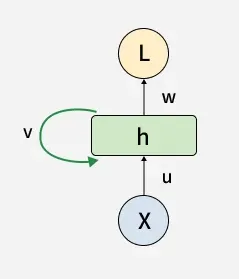

### Lan truyền xuôi

Công thức cơ bản tại bước thời gian $t$:

$$h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)$$

$$y_t = W_{hy}h_t + b_y$$

Trong đó:

* $x_t$: đầu vào tại bước $t$ (ví dụ embedding của từ thứ $t$)
* $h_{t-1}$: hidden state từ bước trước (bộ nhớ tích lũy)
* $h_t$: hidden state mới, vừa chứa thông tin hiện tại vừa mang thông tin quá khứ
* $W_{xh}, W_{hh}, W_{hy}$: các trọng số được chia sẻ (shared weights) across mọi bước thời gian — đây là điểm mấu chốt giúp RNN xử lý được chuỗi có độ dài bất kỳ mà không cần tăng số tham số.

### Lan truyền ngược theo thời gian

RNN vốn có cấu trúc lặp (recurrent): cùng một bộ trọng số $W_{xh}, W_{hh}, W_{hy}$ được dùng lại ở mọi bước thời gian. Để tính được gradient, ta không thể áp dụng backprop thông thường trực tiếp lên một vòng lặp — ta phải unroll (trải) RNN theo trục thời gian thành một đồ thị tính toán (computational graph) tuyến tính, giống như một mạng feedforward rất sâu với $T$ lớp (T = độ dài chuỗi), trong đó mỗi "lớp" tương ứng với một bước thời gian và chia sẻ chung trọng số.

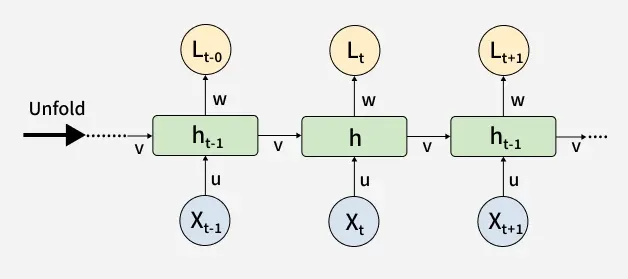

Vì $W_{hh}$ được dùng lại ở mọi bước thời gian ($h_1, h_2, ..., h_T$ đều được tính bằng cùng một $W_{hh}$), nên theo quy tắc đạo hàm của tham số dùng chung (shared parameter), gradient tổng theo $W_{hh}$ phải là tổng gradient cục bộ tại từng lần sử dụng nó:

$$\frac{\partial L}{\partial W_{hh}} = \sum_{t=1}^{T} \frac{\partial L_t}{\partial W_{hh}}$$

Nhưng mỗi $\frac{\partial L_t}{\partial W_{hh}}$ lại không chỉ phụ thuộc vào $W_{hh}$ tại bước $t$, mà còn phụ thuộc gián tiếp qua $h_{t-1}, h_{t-2}, ..., h_1$ — vì $h_{t-1}$ cũng được tính từ $W_{hh}$ ở bước trước đó. Ta phải tổng hợp đóng góp từ mọi bước $k \le t$:

$$\frac{\partial L_t}{\partial W_{hh}} = \sum_{k=1}^{t} \frac{\partial L_t}{\partial h_t} \cdot \frac{\partial h_t}{\partial h_k} \cdot \left. \frac{\partial h_k}{\partial W_{hh}} \right\vert{}_{\text{trực tiếp tại bước } k}$$

$$\frac{\partial h_t}{\partial h_k} = \prod_{i=k+1}^{t} \frac{\partial h_i}{\partial h_{i-1}}$$

$$W_{hh} = W_{hh} - \text{lr} \cdot \frac{\partial L}{\partial W_{hh}}$$

### Các dạng đầu vào - ra

**a. One-to-Many (1 đầu vào → Chuỗi đầu ra)**

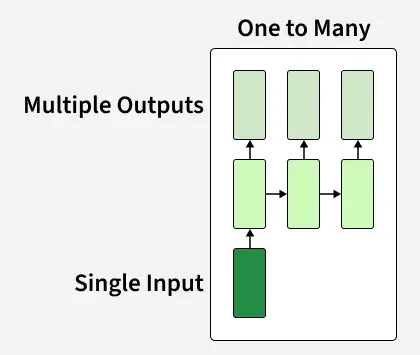

Mạng chỉ nhận một đầu vào duy nhất ở bước thời gian đầu tiên, sau đó tự sinh ra một chuỗi đầu ra kéo dài qua nhiều bước thời gian. Ở các bước sau, mạng thường lấy chính đầu ra của bước trước làm đầu vào cho bước tiếp theo.

* **Cách hoạt động:** Dữ liệu tĩnh được chuyển đổi thành trạng thái ẩn ban đầu ($h_0$), sau đó RNN liên tục giải mã trạng thái này thành các phần tử tuần tự.
* **Ví dụ (Image Captioning - Sinh chú thích ảnh):** Đầu vào là một bức ảnh (đã được nén thành một vector đặc trưng qua mạng CNN). Đầu ra là một chuỗi các từ mô tả bức ảnh đó (ví dụ: "Một", "con", "mèo", "đang", "ngủ").

**b. Many-to-One (Chuỗi đầu vào → 1 đầu ra)**

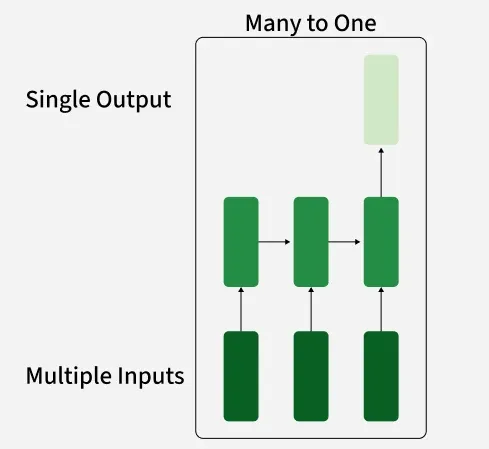

Mạng nhận một chuỗi dữ liệu qua nhiều bước thời gian, nhưng chỉ quan tâm và xuất ra một kết quả duy nhất ở bước cuối cùng, sau khi đã "đọc" hết toàn bộ chuỗi.

* **Ví dụ (Text Classification / Sentiment Analysis):** Đầu vào là một câu bình luận ("Bộ phim này quá tệ và lãng phí thời gian"). Mạng đọc từng từ một, và ở bước cuối cùng, xuất ra một nhãn duy nhất: Tiêu cực.

**c. Many-to-Many (Đồng bộ / Synchronous)**

 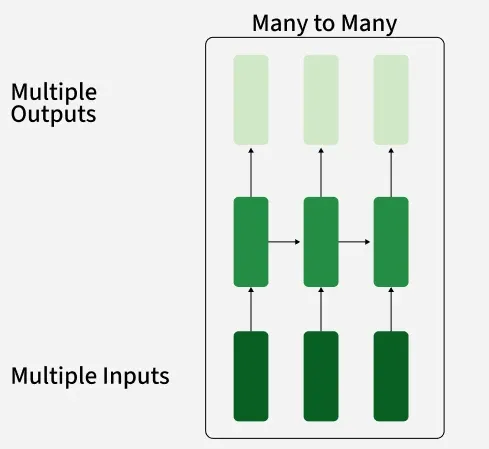

Kiến trúc này nhận một chuỗi đầu vào và sinh ra một chuỗi đầu ra có cùng độ dài. Tại mỗi một bước thời gian $t$, ngay khi nhận một phần tử đầu vào $x_t$, mạng sẽ ngay lập tức xuất ra một kết quả tương ứng $y_t$.

* **Cách hoạt động:** Quá trình đọc đầu vào và xuất đầu ra diễn ra song song (real-time) theo từng bước.
* **Ví dụ (POS Tagging - Gán nhãn từ loại):** Đầu vào là câu "Tôi đang chạy". Ở bước 1 (nhận "Tôi") -> xuất "Đại từ". Bước 2 (nhận "đang") -> xuất "Phó từ". Bước 3 (nhận "chạy") -> xuất "Động từ". Số lượng từ đầu vào luôn bằng số lượng nhãn đầu ra.
* **Ví dụ khác:** Phân tích chuỗi thời gian chứng khoán (nhận giá hôm nay, dự đoán giá ngày mai, lặp lại liên tục).

**d. Many-to-Many (Lệch pha / Asynchronous / Encoder-Decoder)**

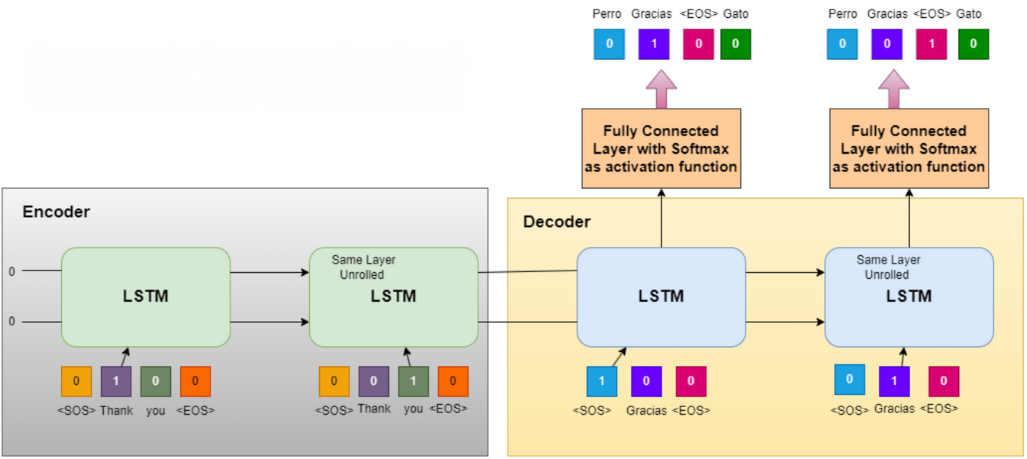

Dùng khi chuỗi đầu vào và chuỗi đầu ra có độ dài khác nhau và không có sự tương ứng 1-1 tại từng bước. Nó được ghép từ hai mạng RNN: một Encoder (Mã hóa) và một Decoder (Giải mã).

* **Cách hoạt động:**
* **Giai đoạn Encode:** RNN đầu tiên (Encoder) hoạt động như dạng Many-to-One. Nó đọc toàn bộ chuỗi đầu vào và nén tất cả ngữ cảnh thành một vector duy nhất (gọi là Context Vector).

* **Giai đoạn Decode:** RNN thứ hai (Decoder) hoạt động như dạng One-to-Many. Nó lấy Context Vector này làm trạng thái ban đầu và bắt đầu sinh ra chuỗi đầu ra cho đến khi gặp tín hiệu "Kết thúc" (EOS - End of Sentence).


* **Ví dụ (Dịch máy - Machine Translation):** Dịch câu tiếng Việt "Xin chào" (2 từ) sang tiếng Anh "Hello" (1 từ). Mạng bắt buộc phải đọc hết cụm "Xin chào" để hiểu ngữ cảnh, nén lại, sau đó mới bắt đầu dịch ra tiếng Anh, vì cấu trúc ngữ pháp giữa hai ngôn ngữ thường bị đảo ngược.

## 2. Vì sao RNN phù hợp với văn bản?

* **Văn bản vốn là dữ liệu tuần tự:** Nghĩa của câu phụ thuộc vào thứ tự từ, và RNN xử lý từng token theo đúng thứ tự xuất hiện — khắc phục đúng hạn chế lớn nhất của MLP đã nói ở phần trước.
* **Chia sẻ trọng số qua các bước thời gian:** Giúp mô hình tổng quát hoá quy luật ngôn ngữ mà không phụ thuộc vị trí tuyệt đối của từ trong câu, đồng thời giữ số lượng tham số không đổi dù độ dài câu thay đổi.
* **Hidden state đóng vai trò "bộ nhớ ngữ cảnh":** Tại mỗi bước, mô hình có thể "nhớ" thông tin từ các từ trước đó để hiểu từ hiện tại trong ngữ cảnh (ví dụ: phân biệt nghĩa của từ đa nghĩa dựa vào từ đứng trước).
* **Độ dài đầu vào linh hoạt:** Không cần padding/truncate về một độ dài cố định như MLP.

## 3. Vấn đề vanishing/exploding gradient

$$\frac{\partial h_t}{\partial h_k} = \prod_{i=k+1}^{t} \frac{\partial h_i}{\partial h_{i-1}}$$

* Nếu trị riêng của ma trận $W_{hh}$ nhỏ hơn 1 hoặc dùng hàm kích hoạt tanh/sigmoid (có đạo hàm nhỏ hơn 1) -> vanishing.
* Nếu trị riêng của ma trận $W_{hh}$ lớn hơn 1, đạo hàm của hàm kích hoạt không đủ nhỏ để bù trừ -> exploding.

**Cách khắc phục:**

**Exploding:**

* **Gradient Clipping (Cắt cụt đạo hàm):** Đây là phương pháp tiêu chuẩn. Nếu giá trị chuẩn (norm) của vector đạo hàm vượt qua một ngưỡng (threshold) cho trước, ta sẽ chia tỉ lệ (scale) vector đó xuống để nó không vượt quá ngưỡng, trong khi vẫn giữ nguyên hướng của vector.
* **Truncated BPTT (Cắt ngắn BPTT):** Thay vì lan truyền ngược qua toàn bộ chuỗi $T$ bước, ta chỉ tính đạo hàm lùi về tối đa $K$ bước (với $K < T$).

**Vanishing:**

* **Sử dụng cấu trúc cổng (Gating Mechanisms - LSTM/GRU)**
* **Đổi hàm kích hoạt (Activation Functions)**
* **Skip Connections (Kết nối tắt):** Tương tự như mạng ResNet trong xử lý ảnh, việc thêm các kết nối trực tiếp từ trạng thái ẩn trong quá khứ ($h_{t-k}$) đến trạng thái hiện tại ($h_t$) tạo ra các "đường tắt" ngắn hơn cho đạo hàm lan truyền ngược.

## 4. LSTM
Long Short-Term Memory (LSTM) là một phiên bản cải tiến của Mạng nơ-ron hồi tiếp (RNN), được thiết kế để nắm bắt các phụ thuộc dài hạn trong dữ liệu dạng chuỗi. Nó sử dụng một tế bào bộ nhớ để lưu trữ thông tin qua thời gian, giải quyết những hạn chế của mạng RNN truyền thống.

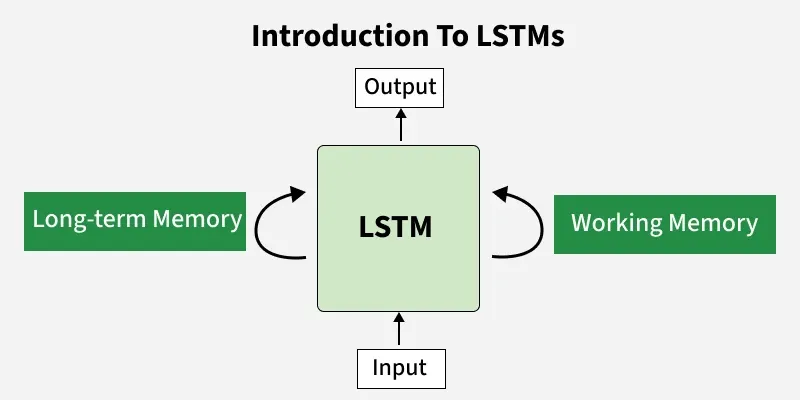!

### Kiến trúc LSTM

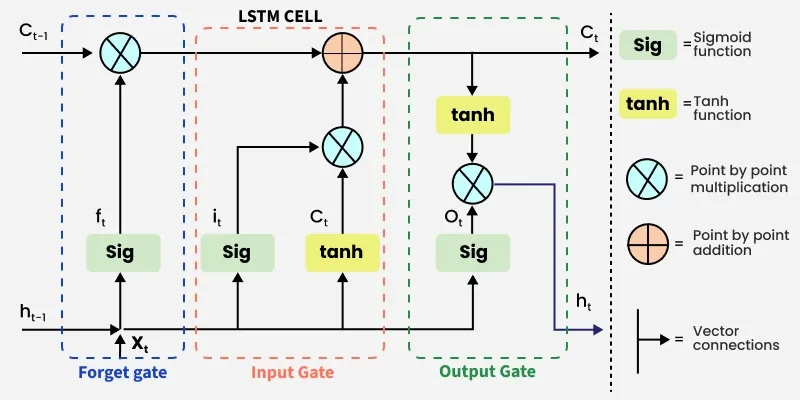

Kiến trúc LSTM (Long Short-Term Memory) được thiết kế để học các phụ thuộc dài hạn trong dữ liệu dạng chuỗi bằng cách sử dụng các tế bào bộ nhớ và các cổng điều khiển luồng thông tin đi qua mạng.

**Các cổng chính trong LSTM**

* **Cổng vào (Input Gate):** Quyết định thông tin mới nào sẽ được thêm vào tế bào bộ nhớ.
* **Cổng quên (Forget Gate):** Xác định thông tin nào sẽ bị loại bỏ khỏi tế bào bộ nhớ.
* **Cổng ra (Output Gate):** Kiểm soát thông tin nào từ tế bào bộ nhớ sẽ được chuyển tiếp sang trạng thái ẩn tiếp theo và làm đầu ra.

**Cách hoạt động của LSTM**
LSTM bao gồm một cấu trúc chuỗi lặp đi lặp lại với các tế bào bộ nhớ và cơ chế cổng.

**Mô hình LSTM**
Thông tin được lưu giữ bởi các tế bào và các thao tác trên bộ nhớ được thực hiện bởi các cổng. Có ba cổng:

#### 1. Cổng quên (Forget Gate)

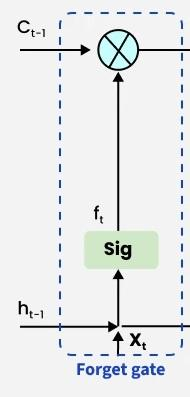

Cổng quên quyết định thông tin nào nên được giữ lại hay loại bỏ khỏi trạng thái tế bào. Nó sử dụng đầu vào hiện tại $x_t$ và trạng thái ẩn trước đó $h_{t-1}$, sau đó áp dụng hàm sigmoid để tạo ra các giá trị nằm trong khoảng từ 0 đến 1.

* Giá trị gần 0 sẽ loại bỏ thông tin.
* Giá trị gần 1 sẽ giữ lại thông tin.
* Giúp loại bỏ những thông tin không cần thiết trong quá khứ.
* Kiểm soát việc lưu giữ bộ nhớ trong LSTM.

Phương trình cho cổng quên là:


$$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$

Trong đó:

* $W_f$ đại diện cho ma trận trọng số liên kết với cổng quên.
* $[h_{t-1}, x_t]$ biểu thị sự kết nối (concatenation) của trạng thái ẩn trước đó và đầu vào hiện tại.
* $b_f$ là độ lệch (bias) của cổng quên.
* $\sigma$ là hàm kích hoạt sigmoid.

#### 2. Cổng vào (Input Gate)

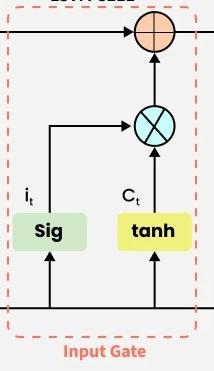

Việc thêm thông tin hữu ích vào trạng thái tế bào được thực hiện bởi cổng vào.
Đầu tiên, thông tin được điều chỉnh bằng hàm sigmoid và lọc ra các giá trị cần ghi nhớ (tương tự như cổng quên) sử dụng các đầu vào $h_{t-1}$ và $x_t$.
Sau đó, một vector được tạo ra bằng hàm tanh, cho kết quả đầu ra từ -1 đến +1, chứa tất cả các giá trị khả thi từ $h_{t-1}$ và $x_t$.
Cuối cùng, các giá trị của vector này và các giá trị đã được điều chỉnh sẽ được nhân với nhau để thu được thông tin hữu ích.

Phương trình cho cổng vào là:


$$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$

$$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$

Ta nhân trạng thái trước đó với $f_t$ để lọc bỏ hiệu quả những thông tin mà ta đã quyết định bỏ qua trước đó. Sau đó, ta cộng thêm $i_t \odot \tilde{C}_t$, biểu thị cho các giá trị ứng viên mới đã được điều chỉnh tỉ lệ theo mức độ ta quyết định cập nhật từng giá trị trạng thái.


$$C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$$

Trong đó:

* $\odot$ biểu thị phép nhân từng phần tử (element-wise multiplication).
* $\tanh$ là hàm kích hoạt.

#### 3. Cổng ra (Output Gate)

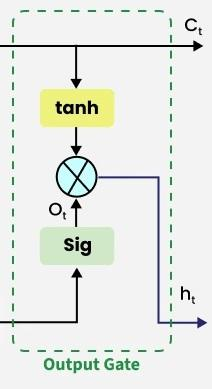

Cổng ra xác định phần thông tin nào từ trạng thái tế bào hiện tại sẽ được truyền đi dưới dạng trạng thái ẩn (đầu ra) tại bước thời gian hiện tại. Nó sử dụng trạng thái ẩn trước đó $h_{t-1}$ và đầu vào hiện tại $x_t$, theo sau là hàm sigmoid để kiểm soát luồng đầu ra.


$$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$

Tiếp theo, trạng thái tế bào hiện tại $C_t$ được đưa qua hàm kích hoạt tanh để điều chỉnh tỉ lệ các giá trị của nó trong khoảng từ -1 đến +1. Cuối cùng, trạng thái tế bào đã được biến đổi này sẽ được nhân từng phần tử với $o_t$ để tạo ra trạng thái ẩn $h_t$:


$$h_t = o_t \odot \tanh(C_t)$$

Trong đó:

* $o_t$ là mức độ kích hoạt của cổng ra.
* $C_t$ là trạng thái tế bào hiện tại.
* $\odot$ đại diện cho phép nhân từng phần tử.
* $\sigma$ là hàm kích hoạt sigmoid.

Trạng thái ẩn $h_t$ này sau đó được chuyển đến bước thời gian tiếp theo và cũng có thể được sử dụng để tạo ra đầu ra của mạng.

## 5. GRU


GRU là một phiên bản đơn giản hóa của mạng LSTM. Chúng kết hợp cổng vào (input gate) và cổng quên (forget gate) thành một cổng cập nhật (update gate) duy nhất, giúp giảm số lượng tham số và làm cho mô hình ít đòi hỏi năng lực tính toán hơn. Dưới đây là cách thức hoạt động:

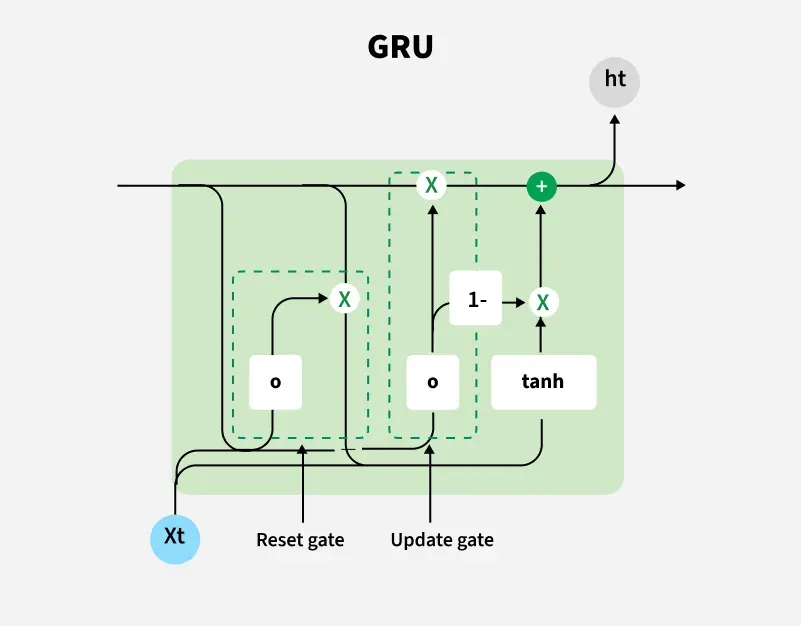

* **Cổng thiết lập lại (Reset Gate - $r_t$):** Quyết định bao nhiêu dữ liệu cũ sẽ đi vào cell hiện tại và có tác động lên việc tạo ra trạng thái ẩn ứng viên.

$$r_t = \sigma(W_r \cdot [h_{t-1}, x_t] + b_r)$$


* **Cổng cập nhật (Update Gate - $z_t$):** Cổng này quyết định lượng thông tin từ quá khứ nên được giữ lại (hoặc quên đi) và thêm bao nhiêu dữ liệu mới vào trạng thái ẩn chính thức.

$$z_t = \sigma(W_z \cdot [h_{t-1}, x_t] + b_z)$$


* **Trạng thái ẩn ứng viên ($\tilde{h}_t$):** Lượng thông tin mới tiềm năng được tạo ra từ đầu vào hiện tại $x_t$ và phần ký ức cũ đã bị lọc qua Reset Gate ($r_t \odot h_{t-1}$).

$$\tilde{h}_t = \tanh(W_h \cdot [r_t \odot h_{t-1}, x_t] + b_h)$$


* **Trạng thái ẩn hiện tại ($h_t$):** Kết hợp tuyến tính giữa ký ức cũ và thông tin ứng viên mới dựa trên tỷ lệ của cổng cập nhật $z_t$.

$$h_t = z_t \odot h_{t-1} + (1 - z_t) \odot \tilde{h}_t$$


## 6. So sánh
| Đặc điểm | RNN | LSTM | GRU |
| --- | --- | --- | --- |
| **Độ phức tạp tính toán (Tham số)** | Thấp nhất (Cấu trúc đơn giản, ít tham số) | Cao nhất (3 cổng: Forget, Input, Output, Cell state riêng) | Trung bình (2 cổng: Reset, Update, không có Cell state riêng) |
| **Khả năng ghi nhớ (Long-term Memory)** | Kém nhất (Dễ bị vanishing gradient với chuỗi dài) | Tốt nhất (Khả năng ghi nhớ dài hạn mạnh mẽ, giữ thông tin qua nhiều bước) | Rất tốt (Gần bằng LSTM, đôi khi tốt hơn trong một số tác vụ cụ thể) |
| **Tốc độ huấn luyện** | Nhanh nhất (Do ít phép toán nhất) | Chậm nhất (Nhiều phép toán ma trận phức tạp nhất) | Nhanh hơn LSTM (Tốn ít thời gian tính toán hơn LSTM do ít cổng hơn) |